# Telco Customer Churn — EDA e baseline

**Objetivo:** priorizar clientes para ações de retenção. Dados públicos de demonstração IBM; não representam uma operadora real em produção. Rótulo `Churn`: cancelamento no último mês. Sem uma data de observação, não é possível afirmar antecipação temporal real.

Métrica técnica principal: **ROC-AUC** na validação cruzada. Secundárias: F1, precisão, recall e average precision. Métrica operacional: recall de churn na lista dos 20% de clientes com maior score. Redução real de cancelamentos exigiria um experimento de campanha.

O teste de 20% fica reservado. A exploração de associações e o baseline abaixo usam apenas treino. O campeão é selecionado no módulo produtivo `churn.train`, com cinco folds e o mesmo pré-processamento.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from threadpoolctl import threadpool_limits
from churn.config import SEED, DATA_PATH
from churn.data import load_data
from churn.pipeline import candidates
X, y = load_data()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Total: {len(X)} | Treino: {len(X_train)} | Teste reservado: {len(X_test)}")
print(f"Features: {X.shape[1]} | Churn no treino: {y_train.mean():.2%}")
figures = ROOT / "reports/figures"
figures.mkdir(parents=True, exist_ok=True)

Total: 7043 | Treino: 5634 | Teste reservado: 1409
Features: 19 | Churn no treino: 26.54%


## Qualidade e distribuição (treino)
`customerID` é validado como único e removido das features; `Churn` nunca é entrada do modelo. Valores vazios de `TotalCharges` são convertidos em ausentes. Imputação por mediana/moda é aprendida dentro de cada fold.

In [2]:
display(pd.DataFrame({"tipo": X_train.dtypes.astype(str), "ausentes": X_train.isna().sum(), "valores_distintos": X_train.nunique()}))
display(X_train.describe())
display(X_train.describe(include="object"))
print("Linhas de features repetidas no treino (podem representar clientes diferentes):", X_train.duplicated().sum())

,tipo,ausentes,valores_distintos
SeniorCitizen,int64,0,2
tenure,int64,0,73
MonthlyCharges,float64,0,1489
TotalCharges,float64,8,5275
gender,object,0,2
Partner,object,0,2
Dependents,object,0,2
PhoneService,object,0,2
MultipleLines,object,0,3
InternetService,object,0,3


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,5634.000000,5634.000000,5634.000000,5626.000000
mean,0.163294,32.485091,64.929961,2302.604266
std,0.369667,24.568744,30.138105,2279.173176
min,0.000000,0.000000,18.400000,18.850000
25%,0.000000,9.000000,35.662500,407.275000
50%,0.000000,29.000000,70.500000,1398.125000
75%,0.000000,55.000000,90.000000,3838.612500
max,1.000000,72.000000,118.750000,8684.800000


,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
count,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4
top,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check
freq,2833,2905,3955,5075,2685,2483,2797,2442,2472,2771,2226,2217,3102,3331,1891


Linhas de features repetidas no treino (podem representar clientes diferentes): 26


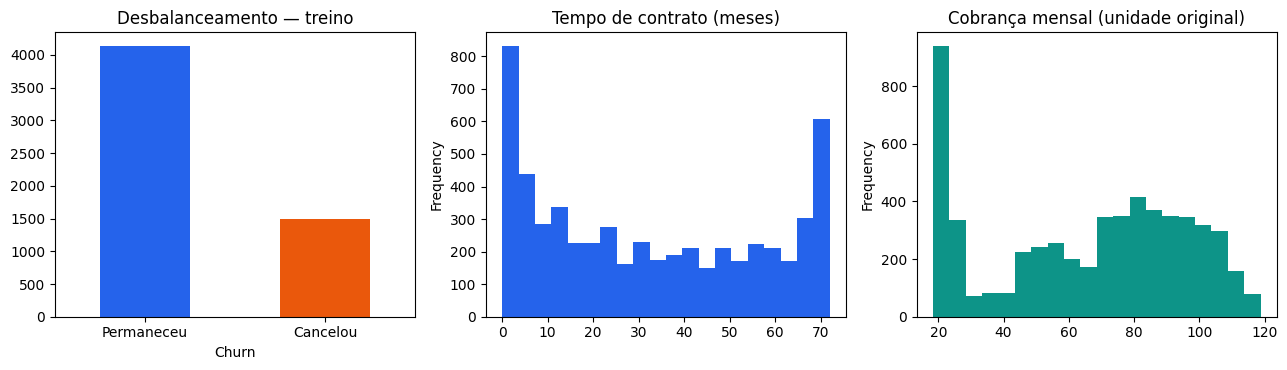

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
y_train.map({0: "Permaneceu", 1: "Cancelou"}).value_counts().plot.bar(ax=axes[0], color=["#2563eb", "#ea580c"], rot=0)
axes[0].set_title("Desbalanceamento — treino")
X_train["tenure"].plot.hist(ax=axes[1], bins=20, color="#2563eb")
axes[1].set_title("Tempo de contrato (meses)")
X_train["MonthlyCharges"].plot.hist(ax=axes[2], bins=20, color="#0d9488")
axes[2].set_title("Cobrança mensal (unidade original)")
fig.tight_layout(); fig.savefig(figures / "eda_distributions.png", dpi=140)
plt.show()

,count,taxa_churn
Contract,,
Month-to-month,3102,0.427466
One year,1173,0.110827
Two year,1359,0.028698


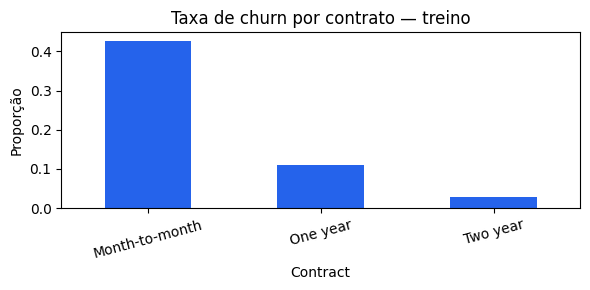

In [4]:
analysis = X_train.assign(Churn=y_train)
summary = analysis.groupby("Contract")["Churn"].agg(["count", "mean"])
display(summary.rename(columns={"mean": "taxa_churn"}))
summary["mean"].plot.bar(figsize=(6, 3), title="Taxa de churn por contrato — treino", color="#2563eb", rot=15)
plt.ylabel("Proporção"); plt.tight_layout()
plt.savefig(figures / "churn_by_contract.png", dpi=140); plt.show()

## Interpretação e decisões

- O desbalanceamento exige métricas além de acurácia; prever sempre permanência pode aparentar bom desempenho.
- Regressão Logística e Random Forest usam pesos de classe. A MLP usa treinamento padrão com early stopping; a comparação registra essas escolhas e não pressupõe igualdade de hiperparâmetros.
- Escala padronizada favorece Regressão Logística e MLP. One-hot evita impor uma ordem artificial nas categorias.
- Contratos e churn podem estar associados; este gráfico **não demonstra causalidade**.
- Ausências em cobrança total não justificam excluir clientes automaticamente; o pipeline imputa usando apenas treino.
- As conclusões se restringem a esta amostra pública. Não se pode estimar receita preservada sem custos, margens e efeito causal de retenção.

## Baseline — Regressão Logística
Validação estratificada de cinco folds; a imputação, o scaler e o encoder são ajustados novamente dentro de cada fold.

In [5]:
baseline = candidates()["logistic_regression"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
with threadpool_limits(limits=1):
    scores = cross_validate(baseline, X_train, y_train, cv=cv, scoring=["roc_auc", "f1", "recall", "precision"], error_score="raise")
display(pd.DataFrame({metric: [scores["test_" + metric].mean(), scores["test_" + metric].std()] for metric in ["roc_auc", "f1", "recall", "precision"]}, index=["média", "desvio padrão"]))

,roc_auc,f1,recall,precision
média,0.845950,0.627927,0.801338,0.516482
desvio padrão,0.012379,0.023225,0.037933,0.018901


## Comparação e avaliação final
Execute `python -m churn.train` antes desta seção. As linhas da tabela são comparadas por CV no treino. O teste abaixo contém somente o campeão já selecionado; não é usado para escolher modelo ou limiar.

,model,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_f1_std,cv_recall_mean,cv_recall_std,cv_precision_mean,cv_precision_std
0,logistic_regression,0.845950,0.012379,0.627927,0.023225,0.801338,0.037933,0.516482,0.018901
1,random_forest,0.845602,0.009015,0.633323,0.018052,0.741137,0.026972,0.553284,0.018600
2,mlp,0.842803,0.010384,0.583842,0.029499,0.523077,0.055264,0.665811,0.017511


Campeão: logistic_regression


roc_auc                                    0.841298
average_precision                          0.632578
f1                                         0.613613
precision                                  0.504303
recall                                     0.783422
accuracy                                   0.738112
recall_at_top_20_percent                   0.497326
precision_at_top_20_percent                0.659574
confusion_matrix_tn_fp_fn_tp    [747, 288, 81, 293]
dtype: object

SHA-256: 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91


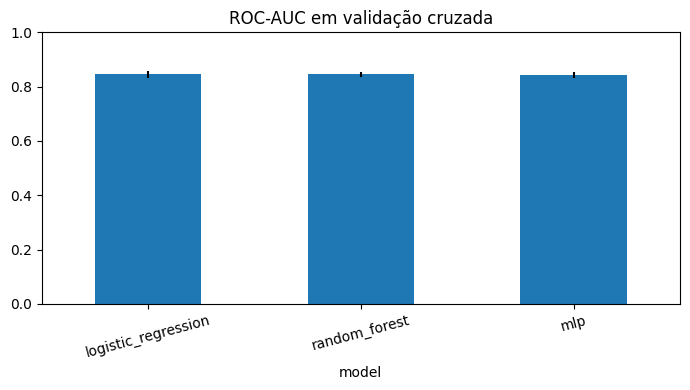

,feature,group,n,roc_auc,average_precision,f1,precision,recall,accuracy,recall_at_top_20_percent,precision_at_top_20_percent,confusion_matrix_tn_fp_fn_tp
0,gender,Female,687,0.837490,0.633270,0.630252,0.530035,0.777202,0.743814,0.481865,0.673913,"[361, 133, 43, 150]"
1,gender,Male,722,0.846468,0.636021,0.597077,0.479866,0.790055,0.732687,0.519337,0.648276,"[386, 155, 38, 143]"
2,SeniorCitizen,0,1187,0.841777,0.614916,0.573864,0.471963,0.731884,0.747262,0.539855,0.626050,"[685, 226, 74, 202]"
3,SeniorCitizen,1,222,0.780036,0.690166,0.725100,0.594771,0.928571,0.689189,0.326531,0.711111,"[62, 62, 7, 91]"


In [6]:
import json
comparison = pd.read_csv(ROOT / "reports/model_comparison.csv")
metadata = json.loads((ROOT / "reports/metrics.json").read_text())
display(comparison)
print("Campeão:", metadata["model_name"])
display(pd.Series(metadata["test_metrics"]))
print("SHA-256:", metadata["dataset_sha256"])
comparison.plot.bar(x="model", y="cv_roc_auc_mean", yerr="cv_roc_auc_std", legend=False, ylim=(0, 1), title="ROC-AUC em validação cruzada", figsize=(7, 4), rot=15)
plt.tight_layout(); plt.savefig(figures / "model_comparison.png", dpi=140); plt.show()
display(pd.read_csv(ROOT / "reports/subgroup_metrics.csv"))

## Limitações e próximos passos

Confira `docs/MODEL_CARD.md` para performance medida, grupos, riscos e uso pretendido. A inspeção por gênero e SeniorCitizen tem finalidade descritiva e não certifica equidade. Próximos passos: coorte temporal real, ajuste de limiar apenas em validação, calibração das probabilidades, intervalos de confiança, auditoria de vieses e teste A/B de retenção. O teste atual não deve ser reutilizado para ajustar decisões.

## Perguntas para continuar a investigação

A acurácia do campeão é próxima da proporção de permanência. Isso não torna os modelos equivalentes: o baseline que prevê sempre permanência não encontra nenhum cancelamento. Precisamos olhar também recall, precisão e o ranking.

O notebook **02_erros_e_limiares.ipynb** explora o custo de mudar a lista de risco, sem usar o teste final. O notebook **03_cenarios_da_api.ipynb** mostra sucessos e erros esperados no contrato da API.

As saídas acima são da primeira execução entregue; esta revisão acrescentou apenas este texto a este notebook. As novas execuções estão nos notebooks 02 e 03.